In [1]:
from importlib import reload
import plotting_utils as pu

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

freq = 32

cell_types = ["Exc", "Pvalb", "Sst", "Vip", "Htr3a"]
colors = [
    "tab:red",
    "tab:blue",
    "tab:green",
    "tab:purple",
    "tab:purple",
]
layers = ["L1", "L2/3", "L4", "L5", "L6"]

cell_labels = {
    "Exc": "Exc",
    "Pvalb": "Pvalb",
    "Sst": "Sst",
    "Vip": "Vip",
    "Htr3a": "L1 Inh",
}

## Fig 3 suppl: firing rates distribution for inhibitory population silencing

In [2]:
net_name = "core"  # change to "core_<variant>" for a model variant
Perturb_dict = {
    "no perturb": "_checkpoint",
    "silencing Vip": "_-2000_silencing_Vip_100perc_checkpoint",
    "silencing Pvalb": "_-2000_silencing_Pvalb_100perc_checkpoint",
    "silencing Sst": "_-2000_silencing_Sst_100perc_checkpoint",
    "silencing i23Vip": "_-2000_silencing_i23Vip_100perc_checkpoint",
    "silencing i23Pvalb": "_-2000_silencing_i23Pvalb_100perc_checkpoint",
    "silencing i23Sst": "_-2000_silencing_i23Sst_100perc_checkpoint",
    "silencing i4Vip": "_-2000_silencing_i4Vip_100perc_checkpoint",
    "silencing i4Pvalb": "_-2000_silencing_i4Pvalb_100perc_checkpoint",
    "silencing i4Sst": "_-2000_silencing_i4Sst_100perc_checkpoint",
    "silencing i5Vip": "_-2000_silencing_i5Vip_100perc_checkpoint",
    "silencing i5Pvalb": "_-2000_silencing_i5Pvalb_100perc_checkpoint",
    "silencing i5Sst": "_-2000_silencing_i5Sst_100perc_checkpoint",
    "silencing i6Vip": "_-2000_silencing_i6Vip_100perc_checkpoint",
    "silencing i6Pvalb": "_-2000_silencing_i6Pvalb_100perc_checkpoint",
    "silencing i6Sst": "_-2000_silencing_i6Sst_100perc_checkpoint",
}

config_files_path = f"{net_name}/configs"


def get_condition_color(condition):
    if condition == "no perturb":
        return "white"
    elif "Vip" in condition:
        return "tab:purple"
    elif "Pvalb" in condition:
        return "tab:blue"
    elif "Sst" in condition:
        return "tab:green"
    return "gray"


perturb_palette = {cond: get_condition_color(cond) for cond in Perturb_dict}

no perturb
inferring network from core


silencing Vip
inferring network from core


silencing Pvalb
inferring network from core


silencing Sst
inferring network from core


silencing i23Vip
inferring network from core


silencing i23Pvalb
inferring network from core


... (7 outputs left out)

silencing i6Vip
inferring network from core


silencing i6Pvalb
inferring network from core


silencing i6Sst
inferring network from core


/tmp/ipykernel_3697999/3225201610.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([t.get_text().replace("L1 Htr3a", "L1 Inh.") for t in ax.get_xticklabels()], rotation=45)


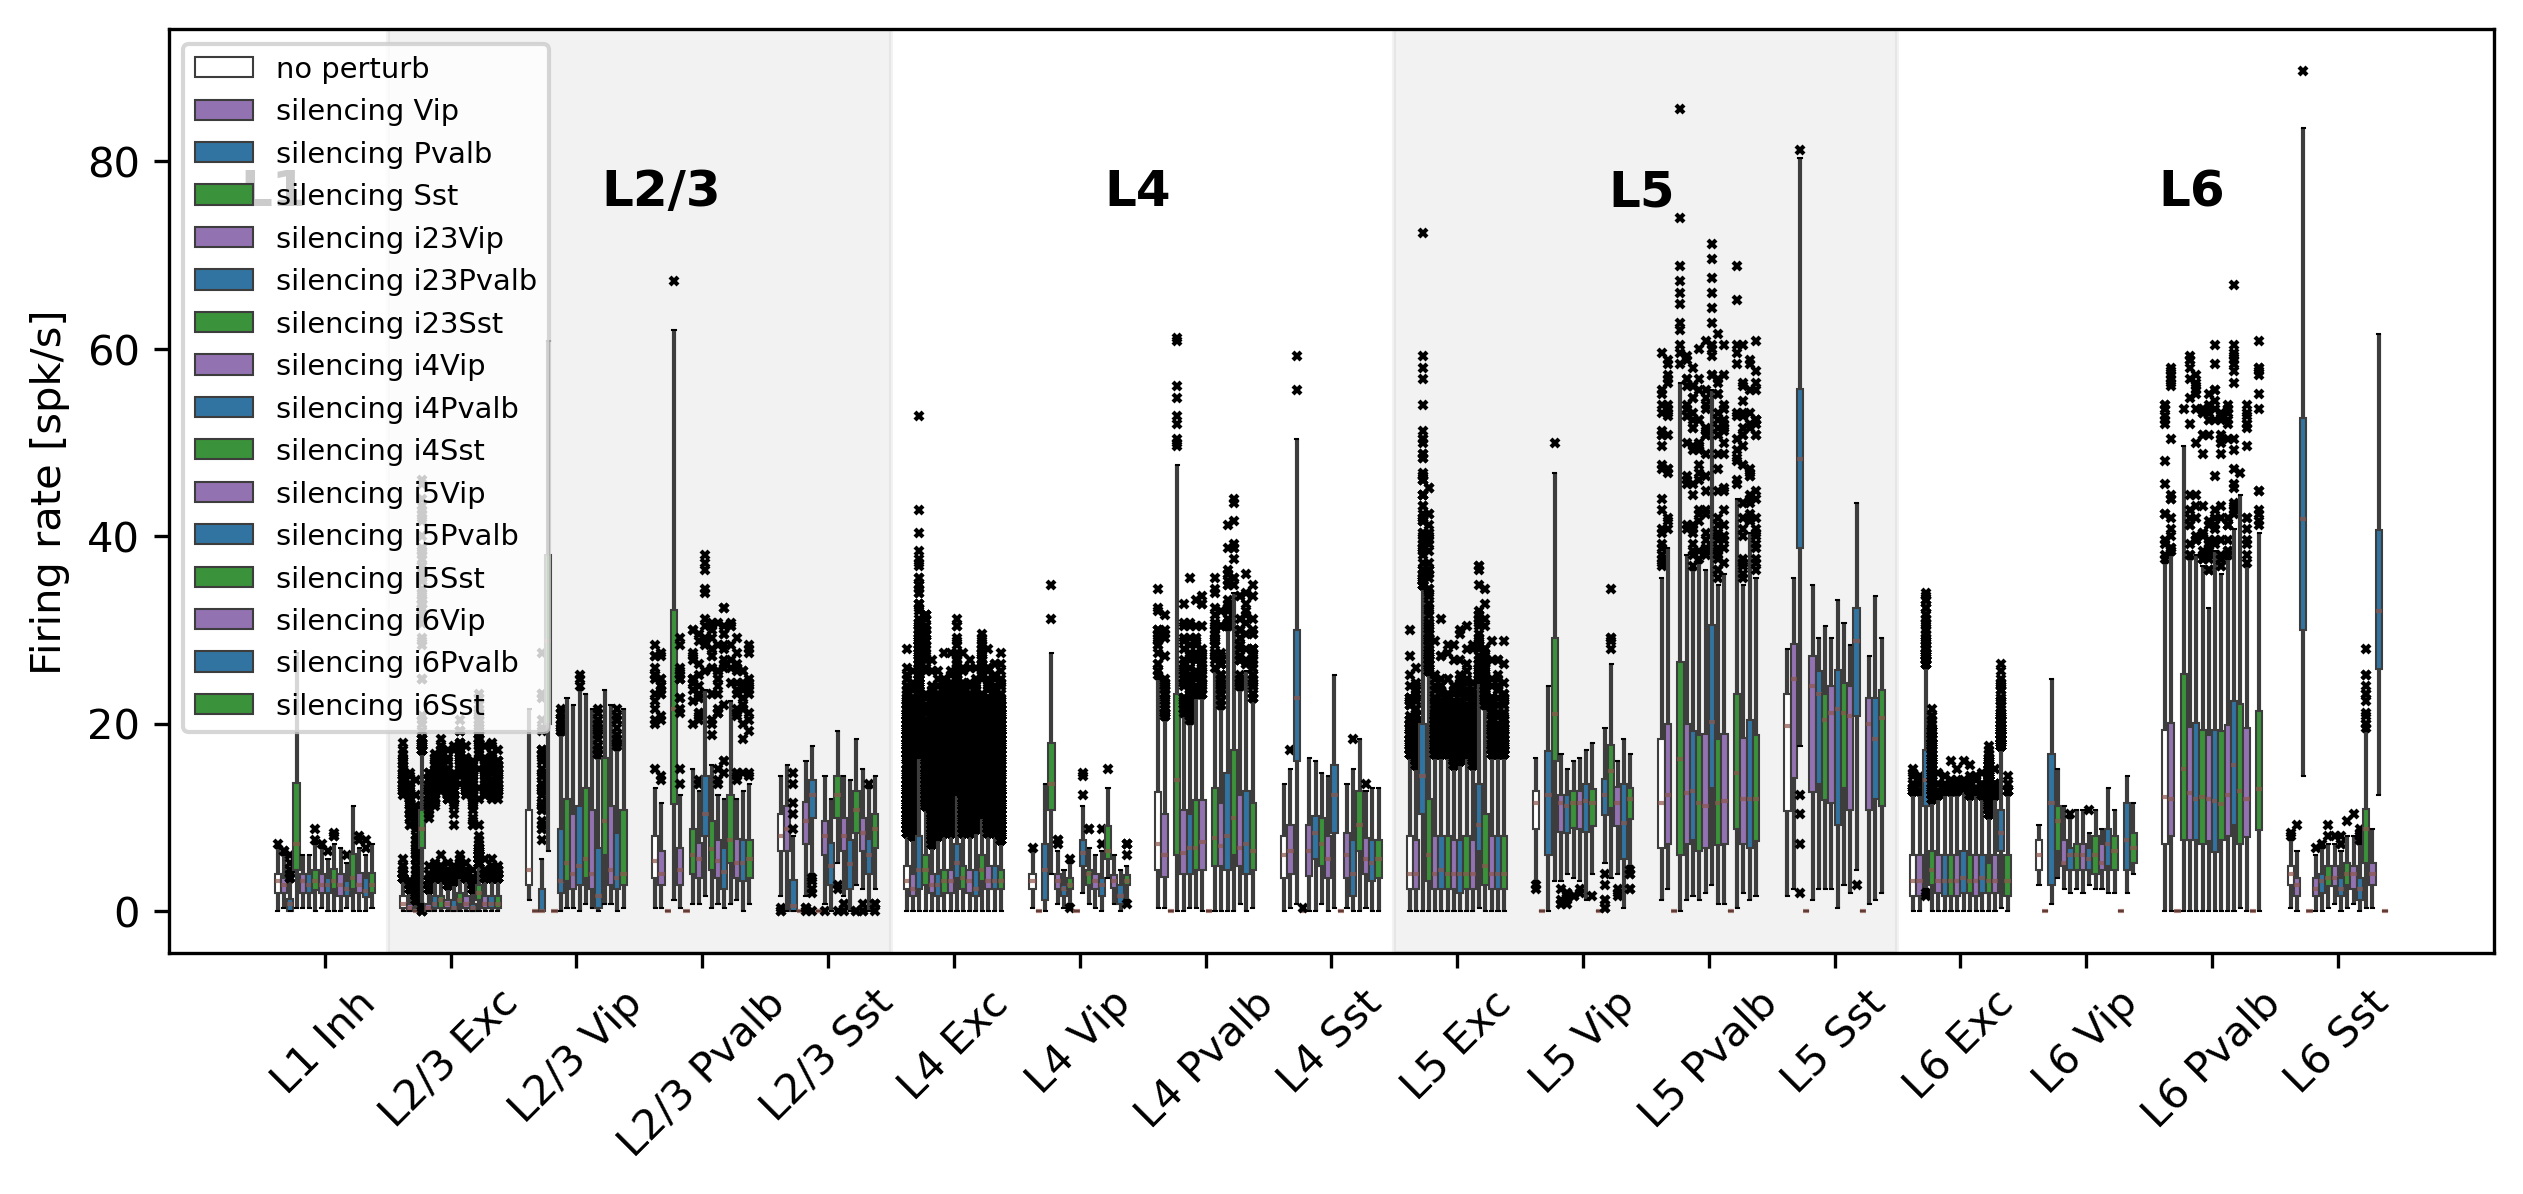

In [3]:
v1df_all = pd.DataFrame()
for condition, file_info in Perturb_dict.items():
    print(condition)
    file_name = (
        config_files_path
        + f"/8dir_10trials{file_info}"
        + "/config_0.json"
    )
    v1df, spike_df = pu.data_organize(
        file_name, t_min=500, t_max=3000, radius=pu.settings["core"]["radius"]
    )
    v1df["condition"] = condition
    v1df_all = pd.concat([v1df_all, v1df])

v1df_all["cell_type"] = v1df_all["cell_type"].map(cell_labels)

v1df_all["cell_layer"] = v1df_all.apply(
    lambda row: row["layer"] + " " + row["cell_type"] if row["layer"] != "L1" else "L1 Inh", axis=1
)

fig, ax = plt.subplots(figsize=(10, 4), dpi=300)
fig.patch.set_facecolor("none")
sns.boxplot(
    ax=ax,
    data=v1df_all,
    x="cell_layer",
    y="fr_stimulus",
    hue="condition",
    palette=perturb_palette,
    flierprops=dict(marker="x", markeredgecolor="black", markersize=2, zorder=2),
    medianprops=dict(color="tab:brown", alpha=0.7, zorder=2),
    boxprops=dict(linewidth=0.5, zorder=2),
    capprops=dict(color="black", linewidth=0.5, zorder=2),
    order=v1df_all["cell_layer"].unique().tolist(),
)
# plt.ylim([-1, 400])
plt.legend(fontsize="x-small")  # , bbox_to_anchor=(1.1, 1), loc='upper center', ncol=1)
ax.set_xticklabels([t.get_text().replace("L1 Htr3a", "L1 Inh.") for t in ax.get_xticklabels()], rotation=45)
plt.xlabel(None)
plt.ylabel("Firing rate [spk/s]")

# plot background layer divider
layer_sep = np.cumsum(v1df_all.groupby("layer")["cell_type"].nunique().values) - 0.5
for i in range(1, len(layer_sep), 2):
    ax.axvspan(layer_sep[i - 1], layer_sep[i], color="gray", alpha=0.1)
# plot layer text
xlim = ax.get_xlim()
ylim = ax.get_ylim()
layer_sep = np.insert(layer_sep, 0, xlim[0])
layer_sep[-1] = xlim[1]
layers = ["L1", "L2/3", "L4", "L5", "L6"]
for i in range(1, len(layer_sep)):
    plt.text(
        (layer_sep[i - 1] + layer_sep[i]) / 2 - 0.3,
        ylim[1] * 0.8,
        layers[i - 1],
        fontsize=12,
        weight="bold",
    )

### Condensed heatmap version of Fig. S3 A–D (reviewer response)

One small **anatomical heatmap per perturbation**, arranged in the same four rows
as the original figure (whole-population, then layer-specific Pvalb / Sst / Vip).
Within each subplot the **y-axis is layer** and the **x-axis is cell type**
(Exc, Pvalb, Sst, Vip; L1 Htr3a is shown in the Vip column), and **pixel color is
the mean stimulus-evoked firing rate normalized to the no-perturbation
condition** (fold change). The subplot title is the perturbation label, bold
outlines flag ≥ 2-fold changes, and the directly silenced target population is
hatched.

Saved to `paper_figs/fig3_suppl_dg_firing_rate_heatmap_norm_inh_pop_sil_July16_2026.pdf`.

## Fig 2 suppl: merged firing-rate distributions (stimuli + inhibitory silencing)

Single stacked figure with a **common x axis** (population = layer × cell type).
Top panel = firing-rate distributions across **visual-stimulus conditions**
(from `fig2CD_dg_rasters_nat_stim_plasma`), followed by the four **inhibitory
silencing** distribution panels from `fig3A_dg_rasters_inh_pop_sil`
(whole-population, then layer-specific Pvalb / Sst / Vip). Panel titles,
palettes (plasma for stimuli; white/purple/green/blue and per-cell-type shades
for silencing), and legend labels are taken from the original notebooks.

Saved to `paper_figs/fig2_suppl_fr_dist_merged_stim_silencing_July16_2026.pdf`.

In [4]:
# ---- stimulus-condition firing rates (from fig2CD_dg_rasters_nat_stim_plasma) ----
# Loaded into `v1df_stim` so the merged figure below can show visual-stimulus
# distributions alongside the silencing distributions (`v1df_all`).
stim_Perturb_dict = {
    "drifting gratings": "8dir_10trials_checkpoint",
    "natural scenes": "natural_scenes_10trials_checkpoint",
    "natural movie one": "natural_movie_one_10trials_checkpoint",
    "natural movie two": "natural_movie_two_10trials_checkpoint",
}

v1df_stim = pd.DataFrame()
for condition, file_info in stim_Perturb_dict.items():
    print(condition)
    file_name = config_files_path + f"/{file_info}" + "/config_0.json"
    v1df, spike_df = pu.data_organize(
        file_name, t_min=500, t_max=3000, radius=pu.settings["core"]["radius"]
    )
    v1df["condition"] = condition
    v1df_stim = pd.concat([v1df_stim, v1df])

v1df_stim["cell_type"] = v1df_stim["cell_type"].map(cell_labels)

v1df_stim["cell_layer"] = v1df_stim.apply(
    lambda row: row["layer"] + " " + row["cell_type"] if row["layer"] != "L1" else "L1 Inh", axis=1
)
layer_cell = v1df_stim["cell_layer"].unique().tolist()

drifting gratings
inferring network from core


natural scenes
inferring network from core


natural movie one
inferring network from core


natural movie two
inferring network from core


/tmp/ipykernel_3697999/204345580.py:101: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[-1].set_xticklabels([t.get_text().replace("L1 Htr3a", "L1 Inh.") for t in axes[-1].get_xticklabels()])


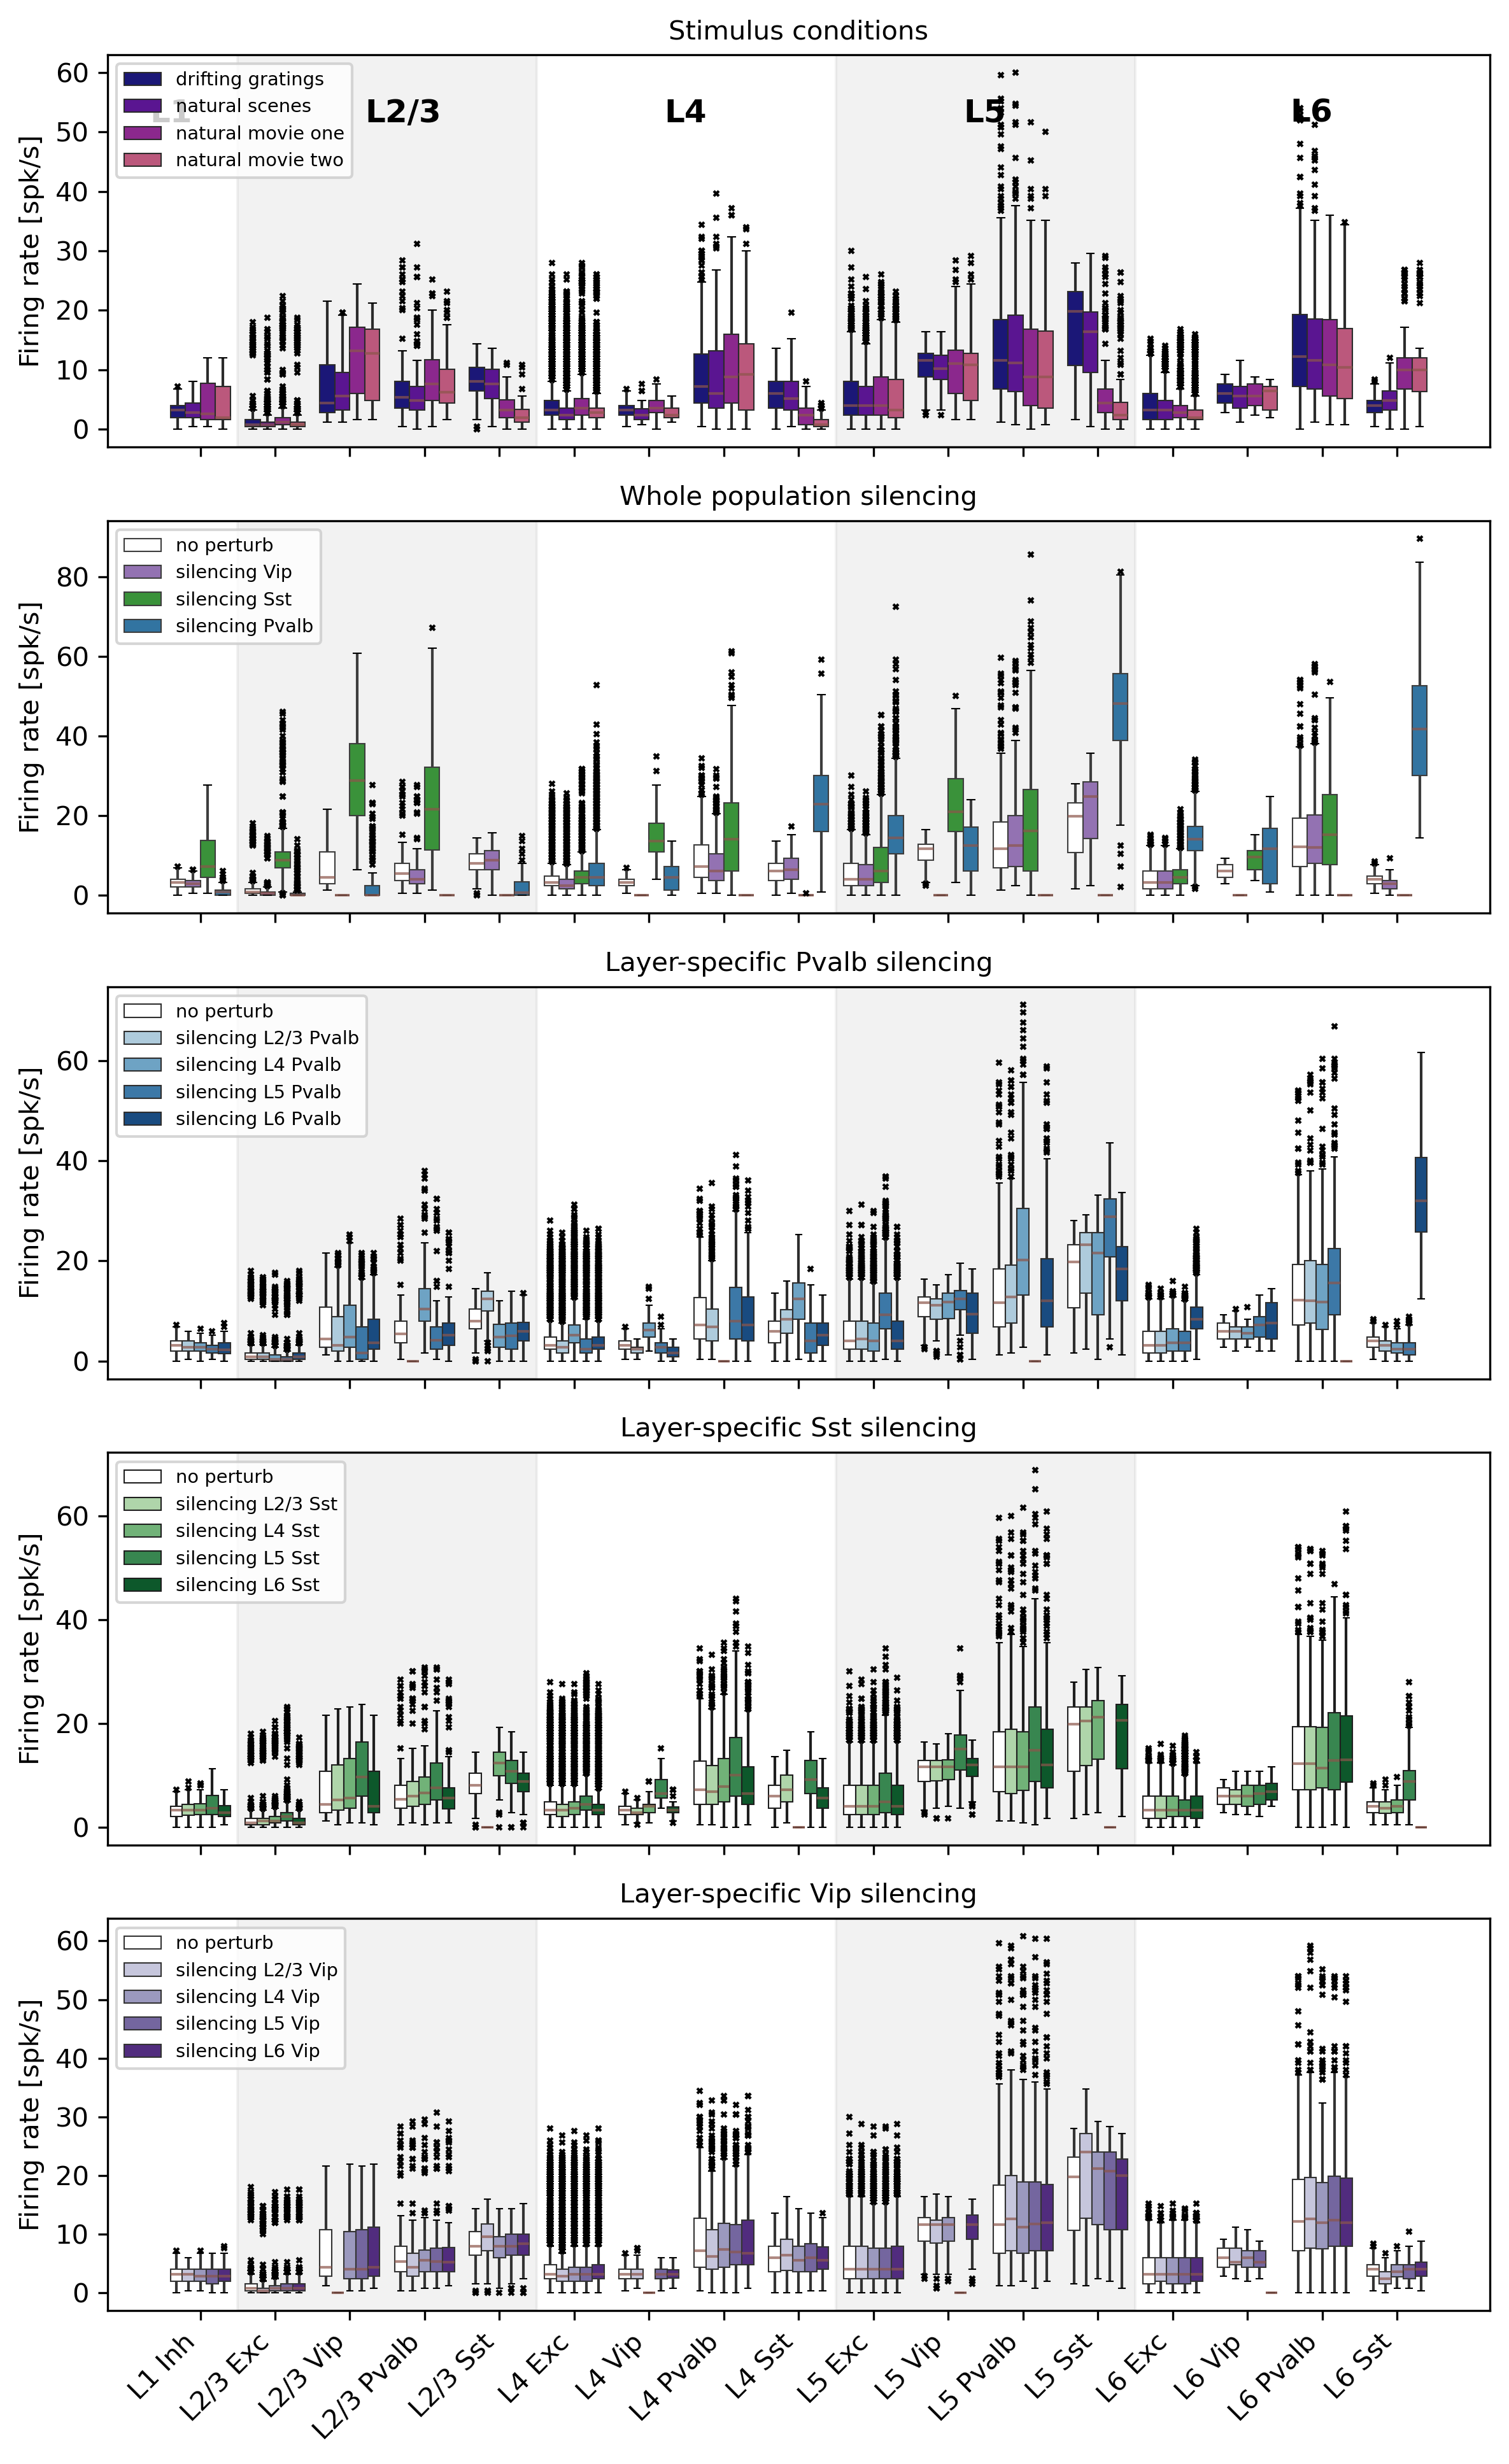

In [5]:
# ===========================================================================
# Merged supplementary firing-rate distribution figure.
# Stacks the visual-stimulus distributions (from fig2CD) on top of the four
# inhibitory-silencing distributions (from fig3A), sharing a common x axis
# (population = layer x cell type).  Palettes/titles match the source notebooks.
# Reuses `v1df_all` (silencing, built above) and `v1df_stim` (stimuli, above).
# ===========================================================================
# stimulus-condition palette (plasma), matching fig2CD
stim_order = list(stim_Perturb_dict.keys())
stim_colors = np.delete(plt.colormaps["plasma"](np.linspace(0, 1, 7)), 6, axis=0)
stim_palette = {c: stim_colors[i] for i, c in enumerate(stim_order)}

# whole-population silencing palette, matching fig3A
def _cond_color(c):
    if c == "no perturb":
        return "white"
    if "Vip" in c:
        return "tab:purple"
    if "Pvalb" in c:
        return "tab:blue"
    if "Sst" in c:
        return "tab:green"
    return "gray"
perturb_palette = {c: _cond_color(c) for c in v1df_all["condition"].unique()}

# layer-specific shades, matching fig3A
pvalb_shades = plt.colormaps["Blues"](np.linspace(0.35, 0.9, 4)).tolist()
sst_shades = plt.colormaps["Greens"](np.linspace(0.35, 0.9, 4)).tolist()
vip_shades = plt.colormaps["Purples"](np.linspace(0.35, 0.9, 4)).tolist()

# (data, conditions, palette, title, custom legend labels) per stacked panel
panels = [
    (v1df_stim, stim_order, stim_palette, "Stimulus conditions", None),
    (v1df_all, ["no perturb", "silencing Vip", "silencing Sst", "silencing Pvalb"],
     perturb_palette, "Whole population silencing", None),
    (v1df_all, ["no perturb", "silencing i23Pvalb", "silencing i4Pvalb",
                "silencing i5Pvalb", "silencing i6Pvalb"],
     {"no perturb": "white", "silencing i23Pvalb": pvalb_shades[0],
      "silencing i4Pvalb": pvalb_shades[1], "silencing i5Pvalb": pvalb_shades[2],
      "silencing i6Pvalb": pvalb_shades[3]},
     "Layer-specific Pvalb silencing",
     ["no perturb", "silencing L2/3 Pvalb", "silencing L4 Pvalb",
      "silencing L5 Pvalb", "silencing L6 Pvalb"]),
    (v1df_all, ["no perturb", "silencing i23Sst", "silencing i4Sst",
                "silencing i5Sst", "silencing i6Sst"],
     {"no perturb": "white", "silencing i23Sst": sst_shades[0],
      "silencing i4Sst": sst_shades[1], "silencing i5Sst": sst_shades[2],
      "silencing i6Sst": sst_shades[3]},
     "Layer-specific Sst silencing",
     ["no perturb", "silencing L2/3 Sst", "silencing L4 Sst",
      "silencing L5 Sst", "silencing L6 Sst"]),
    (v1df_all, ["no perturb", "silencing i23Vip", "silencing i4Vip",
                "silencing i5Vip", "silencing i6Vip"],
     {"no perturb": "white", "silencing i23Vip": vip_shades[0],
      "silencing i4Vip": vip_shades[1], "silencing i5Vip": vip_shades[2],
      "silencing i6Vip": vip_shades[3]},
     "Layer-specific Vip silencing",
     ["no perturb", "silencing L2/3 Vip", "silencing L4 Vip",
      "silencing L5 Vip", "silencing L6 Vip"]),
]

# layer boundaries from the fixed x order (layer_cell from the first cell)
_counts = [sum(p.startswith(l + " ") for p in layer_cell)
           for l in ["L1", "L2/3", "L4", "L5", "L6"]]
layer_sep = np.cumsum(_counts) - 0.5
layers_list = ["L1", "L2/3", "L4", "L5", "L6"]

fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(8, 13), dpi=300, sharex=True)
fig.patch.set_facecolor("none")
for k, (ax, (df, conds, palette, title, legend_labels)) in enumerate(
        zip(axes, panels)):
    sub = df[df["condition"].isin(conds)]
    sns.boxplot(
        ax=ax, data=sub, x="cell_layer", y="fr_stimulus", hue="condition",
        hue_order=conds, palette=palette, order=layer_cell,
        flierprops=dict(marker="x", markeredgecolor="black", markersize=2, zorder=2),
        medianprops=dict(color="tab:brown", alpha=0.7, zorder=2),
        boxprops=dict(linewidth=0.5, zorder=2),
        capprops=dict(color="black", linewidth=0.5, zorder=2),
    )
    if legend_labels is not None:
        handles, _ = ax.get_legend_handles_labels()
        ax.legend(handles=handles, labels=legend_labels, fontsize="x-small")
    else:
        ax.legend(fontsize="x-small")
    ax.set_xlabel(None)
    ax.set_ylabel("Firing rate [spk/s]")
    ax.set_title(title, fontsize=10)
    # alternate-layer background shading (all panels)
    for i in range(1, len(layer_sep), 2):
        ax.axvspan(layer_sep[i - 1], layer_sep[i], color="gray", alpha=0.1)
    # bold layer labels on the top panel only (x axis is shared)
    if k == 0:
        edges = np.insert(layer_sep, 0, ax.get_xlim()[0])
        edges[-1] = ax.get_xlim()[1]
        ylim = ax.get_ylim()
        for i in range(1, len(edges)):
            ax.text((edges[i - 1] + edges[i]) / 2 - 0.3, ylim[1] * 0.82,
                    layers_list[i - 1], fontsize=12, weight="bold")

axes[-1].set_xticklabels([t.get_text().replace("L1 Htr3a", "L1 Inh.") for t in axes[-1].get_xticklabels()])
axes[-1].tick_params(axis="x", rotation=45)
for lbl in axes[-1].get_xticklabels():
    lbl.set_horizontalalignment("right")
fig.tight_layout()
fig.savefig(
    "paper_figs/fig2_suppl_fr_dist_merged_stim_silencing_July16_2026.pdf",
    dpi=300, bbox_inches="tight", transparent=True,
)